In [1]:
#Load the clean data

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
os.makedirs('../outputs', exist_ok=True)

colors = {'El Niño': 'tab:red', 'La Niña': 'tab:blue', 'Neutral': 'gray'}

enso = pd.read_csv('../data/enso_clean.csv', parse_dates=['date'])
enso['year'] = enso['date'].dt.year
enso['month'] = enso['date'].dt.month
enso['decade'] = (enso['year'] // 10) * 10

print(enso.shape)
enso.head()

(908, 10)


,date,SEAS,oni,nino34_sst,soi,phase_simple,phase,year,month,decade
0,1951-01-01,DJF,-0.66,25.67,2.5,La Niña,Neutral,1951,1,1950
1,1951-02-01,JFM,-0.36,26.20,1.5,Neutral,Neutral,1951,2,1950
2,1951-03-01,FMA,-0.04,26.96,-0.2,Neutral,Neutral,1951,3,1950
3,1951-04-01,MAM,0.16,27.48,-0.5,Neutral,Neutral,1951,4,1950
4,1951-05-01,AMJ,0.27,27.72,-1.1,Neutral,Neutral,1951,5,1950


In [31]:
# Count an ongoing event at the end of the data even if it has fewer than 5 months so far
for sign, label in [(1, 'El Niño'), (-1, 'La Niña')]:
    flag = (enso['oni'] * sign) >= 0.5
    if flag.iloc[-1]:
        rid = (flag != flag.shift()).cumsum()
        enso.loc[rid == rid.iloc[-1], 'phase'] = label

print(enso['phase'].value_counts())

phase
Neutral    481
El Niño    219
La Niña    208
Name: count, dtype: int64


In [32]:
out_cols = ['date', 'SEAS', 'oni', 'nino34_sst', 'soi', 'phase_simple', 'phase']
enso[out_cols].to_csv('../data/enso_clean.csv', index=False, encoding='utf-8-sig')
print('Saved', enso[out_cols].shape)

Saved (908, 7)


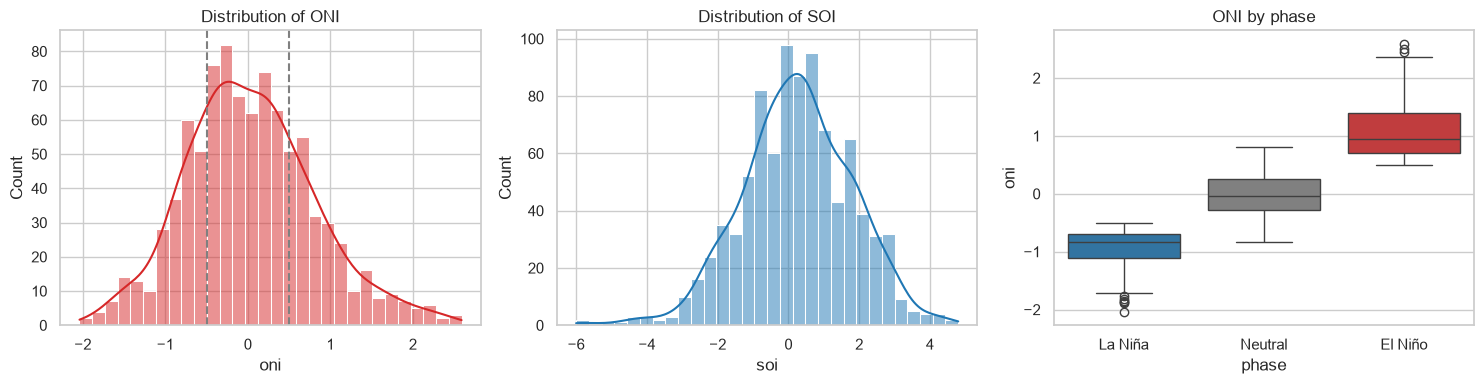

oni    0.37
soi   -0.22
dtype: float64


In [9]:
#Distributions

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(enso['oni'], bins=30, kde=True, color='tab:red', ax=ax[0])
ax[0].axvline(0.5, ls='--', color='gray')
ax[0].axvline(-0.5, ls='--', color='gray')
ax[0].set_title('Distribution of ONI')

sns.histplot(enso['soi'], bins=30, kde=True, color='tab:blue', ax=ax[1])
ax[1].set_title('Distribution of SOI')

sns.boxplot(
    data=enso, x='phase', y='oni', hue='phase',
    order=['La Niña', 'Neutral', 'El Niño'],
    hue_order=['La Niña', 'Neutral', 'El Niño'],
    palette=colors, legend=False, ax=ax[2],
)
ax[2].set_title('ONI by phase')

plt.tight_layout()
plt.savefig('../outputs/fig01_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print(enso[['oni', 'soi']].skew().round(2))

In [10]:
#Build the event table

run_id = (enso['phase'] != enso['phase'].shift()).cumsum().rename('run')

runs = enso.groupby(run_id).agg(
    phase=('phase', 'first'),
    start=('date', 'min'),
    end=('date', 'max'),
    months=('date', 'size'),
    mean_oni=('oni', 'mean'),
    peak_idx=('oni', lambda s: s.abs().idxmax()),
)
runs['peak_oni'] = enso.loc[runs['peak_idx'], 'oni'].values
runs['peak_date'] = enso.loc[runs['peak_idx'], 'date'].values

events = runs[runs['phase'] != 'Neutral'].reset_index(drop=True)
print(len(events), 'events found')

42 events found


In [11]:
#Strength, peak month, and flags

def strength(x):
    a = abs(x)
    if a >= 2.0:
        return 'Very strong'
    if a >= 1.5:
        return 'Strong'
    if a >= 1.0:
        return 'Moderate'
    return 'Weak'

events['strength'] = events['peak_oni'].apply(strength)
events['peak_month'] = events['peak_date'].dt.month
events['start_year'] = events['start'].dt.year
events['decade'] = (events['start_year'] // 10) * 10

# Events that touch the first or last month of the data are cut off,
# so their true length may be longer than what we can measure
first_date = enso['date'].min()
last_date = enso['date'].max()
events['cut_off'] = (events['start'] == first_date) | (events['end'] == last_date)

show = events[['phase', 'start', 'end', 'months', 'peak_oni', 'strength', 'cut_off']].copy()
show['start'] = show['start'].dt.strftime('%Y-%m')
show['end'] = show['end'].dt.strftime('%Y-%m')
show['peak_oni'] = show['peak_oni'].round(2)
show

,phase,start,end,months,peak_oni,strength,cut_off
0,El Niño,1951-06,1952-01,8,1.03,Moderate,False
1,El Niño,1953-04,1953-12,9,0.78,Weak,False
2,La Niña,1955-03,1956-04,14,-1.59,Strong,False
3,El Niño,1957-04,1958-05,14,1.69,Strong,False
4,El Niño,1963-07,1964-02,8,1.19,Moderate,False
5,La Niña,1964-05,1965-01,9,-0.80,Weak,False
6,El Niño,1965-06,1966-03,10,1.82,Strong,False
7,El Niño,1968-10,1969-05,8,0.98,Weak,False
8,La Niña,1970-07,1972-01,19,-1.36,Moderate,False
9,El Niño,1972-06,1973-03,10,1.84,Strong,False


In [12]:
#How many events, how long, how strong

print(events['phase'].value_counts())
print()

complete = events[~events['cut_off']]
print('Duration in months (complete events only):')
print(complete.groupby('phase')['months'].describe().round(1))
print()

print('Events by strength:')
print(pd.crosstab(events['phase'], events['strength']))

phase
El Niño    23
La Niña    19
Name: count, dtype: int64

Duration in months (complete events only):
         count  mean  std  min  25%  50%   75%   max
phase                                               
El Niño   22.0   9.8  4.0  5.0  7.2  9.0  11.8  20.0
La Niña   19.0  10.9  5.6  5.0  6.0  9.0  14.0  24.0

Events by strength:
strength  Moderate  Strong  Very strong  Weak
phase                                        
El Niño          5       6            4     8
La Niña          5       6            1     7


In [13]:
#The strongest events

cols = ['start', 'end', 'months', 'peak_oni', 'strength']

print('Top 5 El Niño events:')
print(events[events['phase'] == 'El Niño'].nlargest(5, 'peak_oni')[cols])
print()
print('Top 5 La Niña events:')
print(events[events['phase'] == 'La Niña'].nsmallest(5, 'peak_oni')[cols])

Top 5 El Niño events:
        start        end  months  peak_oni     strength
34 2014-10-01 2016-05-01      20      2.59  Very strong
22 1997-05-01 1998-04-01      12      2.37  Very strong
41 2026-05-01 2026-08-01       4      2.16  Very strong
14 1982-05-01 1983-06-01      14      2.14  Very strong
40 2023-06-01 2024-04-01      11      1.99       Strong

Top 5 La Niña events:
        start        end  months  peak_oni     strength
10 1973-05-01 1974-06-01      14     -2.04  Very strong
18 1988-05-01 1989-05-01      13     -1.85       Strong
29 2007-08-01 2008-06-01      11     -1.76       Strong
2  1955-03-01 1956-04-01      14     -1.59       Strong
11 1974-10-01 1976-03-01      18     -1.58       Strong


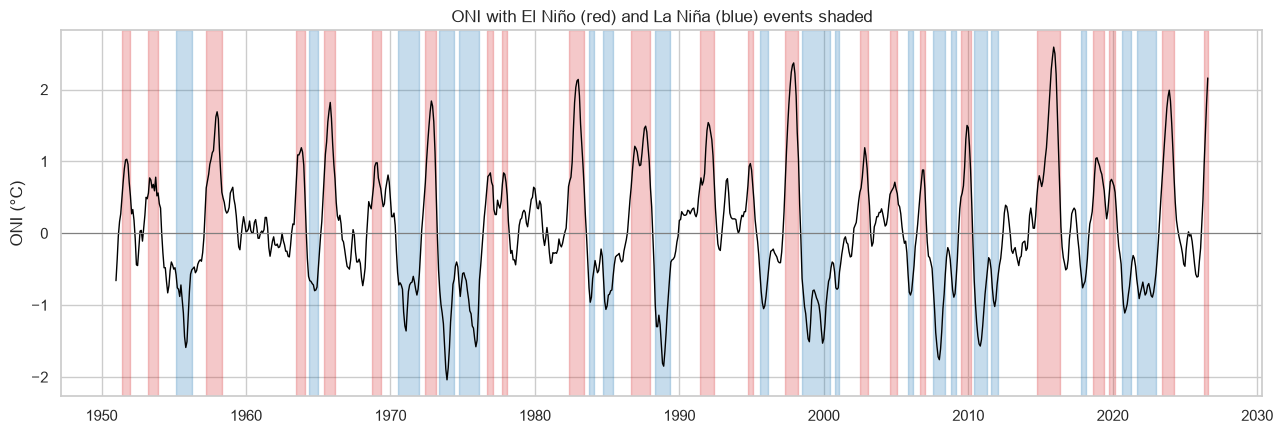

In [14]:
#Timeline of all events

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(enso['date'], enso['oni'], color='black', lw=1)
ax.axhline(0, color='gray', lw=0.8)

for _, e in events.iterrows():
    ax.axvspan(e['start'], e['end'], color=colors[e['phase']], alpha=0.25)

ax.set_title('ONI with El Niño (red) and La Niña (blue) events shaded')
ax.set_ylabel('ONI (°C)')
plt.tight_layout()
plt.savefig('../outputs/fig02_event_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

Events starting in each decade:
phase   El Niño  La Niña
decade                  
1950          3        1
1960          3        1
1970          3        3
1980          2        3
1990          3        2
2000          4        4
2010          3        3
2020          2        2

Percent of months in each phase, by decade:
phase   El Niño  La Niña  Neutral
decade                           
1950       28.7     13.0     58.3
1960       21.7      7.5     70.8
1970       17.5     42.5     40.0
1980       25.8     22.5     51.7
1990       25.0     21.7     53.3
2000       21.7     26.7     51.7
2010       30.0     20.0     50.0
2020       22.5     31.2     46.2

Strong or very strong events by decade:
phase   El Niño  La Niña
decade                  
1950          1        1
1960          1        0
1970          1        2
1980          1        1
1990          2        1
2000          1        1
2010          1        1
2020          2        0


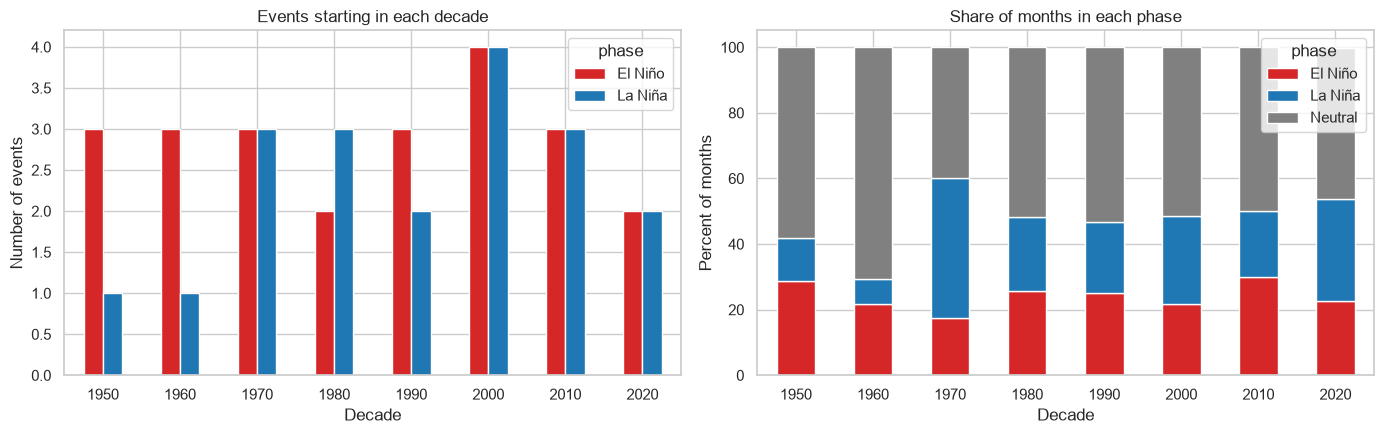

In [15]:
#Frequency change by a decade

by_decade = pd.crosstab(events['decade'], events['phase'])
print('Events starting in each decade:')
print(by_decade)
print()

share_decade = pd.crosstab(enso['decade'], enso['phase'], normalize='index').mul(100).round(1)
print('Percent of months in each phase, by decade:')
print(share_decade)
print()

strong = events[events['strength'].isin(['Strong', 'Very strong'])]
print('Strong or very strong events by decade:')
print(pd.crosstab(strong['decade'], strong['phase']))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
by_decade.plot(kind='bar', color=[colors['El Niño'], colors['La Niña']], ax=ax[0], rot=0)
ax[0].set_title('Events starting in each decade')
ax[0].set_xlabel('Decade')
ax[0].set_ylabel('Number of events')

share_decade.plot(
    kind='bar', stacked=True,
    color=[colors['El Niño'], colors['La Niña'], colors['Neutral']],
    ax=ax[1], rot=0,
)
ax[1].set_title('Share of months in each phase')
ax[1].set_xlabel('Decade')
ax[1].set_ylabel('Percent of months')

plt.tight_layout()
plt.savefig('../outputs/fig03_by_decade.png', dpi=150, bbox_inches='tight')
plt.show()


phase       El Niño  La Niña
peak_month                  
1                 4        3
2                 0        1
3                 0        0
4                 0        0
5                 0        0
6                 0        0
7                 0        0
8                 1        0
9                 1        0
10                2        1
11                6        7
12                9        7


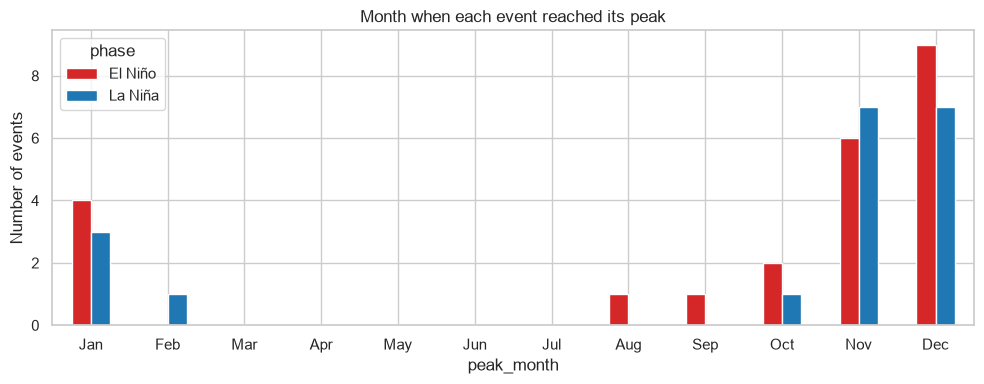

In [16]:
#Events peak

peak_counts = (
    events.groupby(['peak_month', 'phase']).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)
print(peak_counts)

ax = peak_counts.plot(
    kind='bar', color=[colors[c] for c in peak_counts.columns],
    figsize=(10, 4), rot=0,
)
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Month when each event reached its peak')
ax.set_ylabel('Number of events')
plt.tight_layout()
plt.savefig('../outputs/fig04_peak_month.png', dpi=150, bbox_inches='tight')
plt.show()

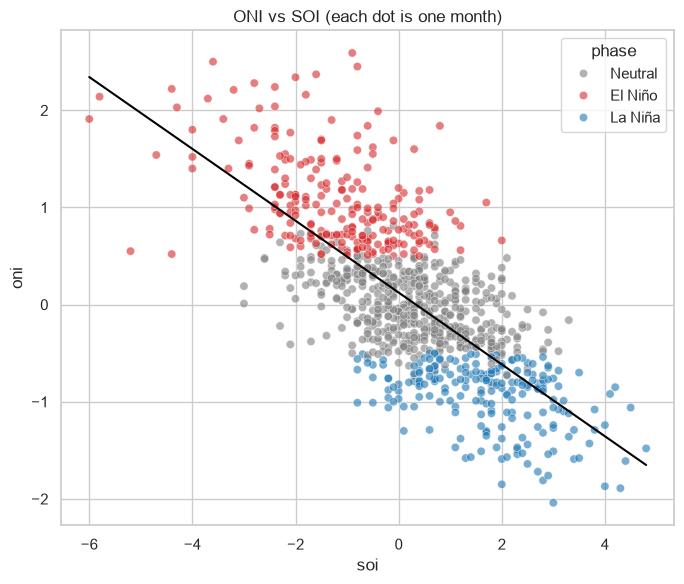

Correlation: -0.73


In [17]:
# ONI and SOI relation plots

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(
    data=enso, x='soi', y='oni', hue='phase',
    palette=colors, alpha=0.6, ax=ax,
)

slope, intercept = np.polyfit(enso['soi'], enso['oni'], 1)
xs = np.linspace(enso['soi'].min(), enso['soi'].max(), 100)
ax.plot(xs, slope * xs + intercept, color='black', lw=1.5)

ax.set_title('ONI vs SOI (each dot is one month)')
plt.tight_layout()
plt.savefig('../outputs/fig05_oni_vs_soi.png', dpi=150, bbox_inches='tight')
plt.show()

print('Correlation:', round(enso['oni'].corr(enso['soi']), 2))

In [18]:
enso['soi_3m'] = enso['soi'].rolling(3, center=True).mean()
print(enso[['oni', 'soi', 'soi_3m']].corr().round(2))

         oni   soi  soi_3m
oni     1.00 -0.73   -0.84
soi    -0.73  1.00    0.87
soi_3m -0.84  0.87    1.00


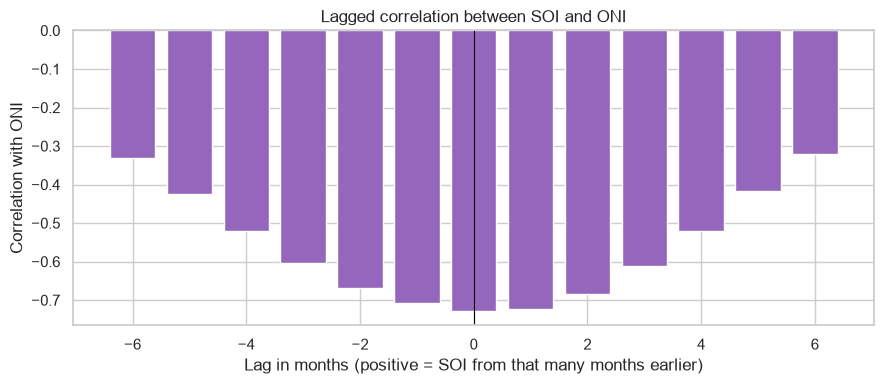

Strongest (most negative) correlation at lag 0 months


In [19]:
lags = list(range(-6, 7))
lag_corr = [enso['oni'].corr(enso['soi'].shift(lag)) for lag in lags]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lags, lag_corr, color='tab:purple')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Lag in months (positive = SOI from that many months earlier)')
ax.set_ylabel('Correlation with ONI')
ax.set_title('Lagged correlation between SOI and ONI')
plt.tight_layout()
plt.savefig('../outputs/fig06_lag_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

best = lags[int(np.argmin(lag_corr))]
print('Strongest (most negative) correlation at lag', best, 'months')

Trend in Niño 3.4 temperature: 0.06 °C per decade


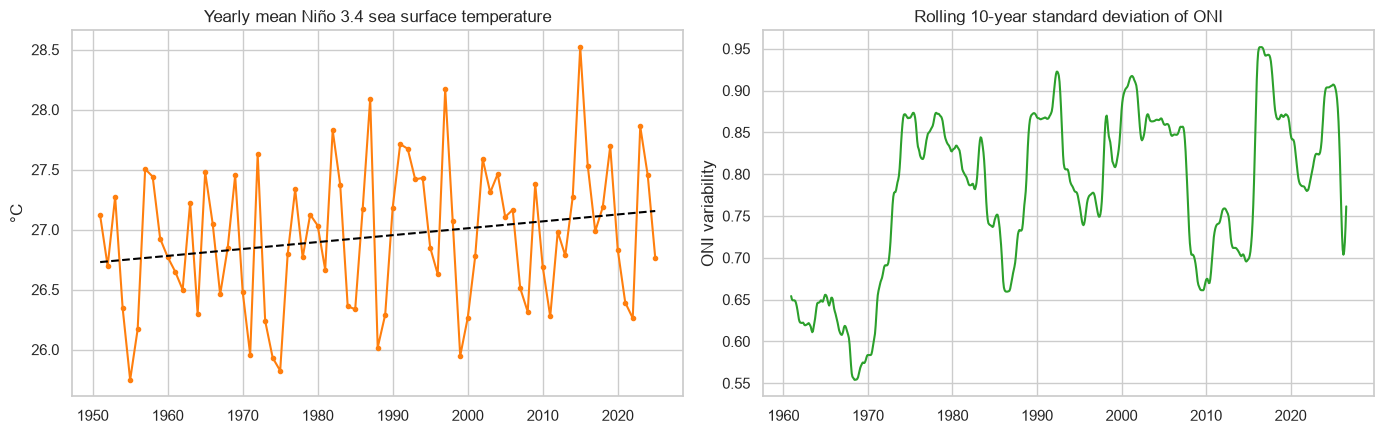

In [20]:
#Long term change

# Average Niño 3.4 temperature per year (left out 2026, since it is incomplete)
yearly = enso[enso['year'] < 2026].groupby('year')['nino34_sst'].mean()
slope, intercept = np.polyfit(yearly.index, yearly.values, 1)
print('Trend in Niño 3.4 temperature:', round(slope * 10, 2), '°C per decade')

# How variable is ENSO over a rolling 10 years?
roll_std = enso.set_index('date')['oni'].rolling(120).std()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(yearly.index, yearly.values, marker='o', ms=3, color='tab:orange')
ax[0].plot(yearly.index, slope * yearly.index + intercept, color='black', ls='--')
ax[0].set_title('Yearly mean Niño 3.4 sea surface temperature')
ax[0].set_ylabel('°C')

ax[1].plot(roll_std.index, roll_std.values, color='tab:green')
ax[1].set_title('Rolling 10-year standard deviation of ONI')
ax[1].set_ylabel('ONI variability')

plt.tight_layout()
plt.savefig('../outputs/fig07_long_term.png', dpi=150, bbox_inches='tight')
plt.show()


In [29]:


# Events table (round only the numeric columns, not the dates)
save_cols = ['phase', 'start', 'end', 'months', 'mean_oni', 'peak_date', 'peak_oni', 'strength', 'cut_off']
out = events[save_cols].copy()
out[['mean_oni', 'peak_oni']] = out[['mean_oni', 'peak_oni']].round(2)
out.to_csv('../outputs/enso_events.csv', index=False)

# Phase summary, recalculated from the current (corrected) labels
counts = enso['phase'].value_counts()
share = (counts / len(enso) * 100).round(1)
summary = pd.DataFrame({'months': counts, 'percent': share})
summary.to_csv('../outputs/phase_summary.csv')

print(summary)
print()
print(os.listdir('../outputs'))

         months  percent
phase                   
Neutral     481     53.0
El Niño     219     24.1
La Niña     208     22.9

['enso_events.csv', 'fig01_distributions.png', 'fig02_event_timeline.png', 'fig03_by_decade.png', 'fig04_peak_month.png', 'fig05_oni_vs_soi.png', 'fig06_lag_correlation.png', 'fig07_long_term.png', 'phase_summary.csv']


## Findings

**How often?**
From January 1951 to August 2026 (908 months), about 24% of months were El Niño, 23% were La Niña, and 53% were Neutral. The Pacific was in an active phase for roughly 47% of the time, and the two phases occurred about equally often.

**How many events, how long, how strong?**
- There were 23 El Niño and 19 La Niña events.
- Both lasted a median of 9 months. La Niña ran slightly longer on average (10.9 vs 9.8 months) and produced the longest event (24 months, vs 20 for El Niño).
- Very strong events were far more common for El Niño (4) than for La Niña (1). Each phase had 6 strong events.
- The strongest El Niños were 2014-16 (peak ONI +2.59), 1997-98 (+2.37), 1982-83 (+2.14) and 2023-24 (+1.99).
- The strongest La Niñas were 1973-74 (-2.04), 1988-89 (-1.85) and 2007-08 (-1.76).

**By decade**
- Each decade had 2 to 4 events of each type, so there is no clear change in how often events start.
- The 1960s were the calmest decade (71% of months Neutral). The 1970s were the most active, with 42.5% of months in La Niña.
- The 2010s had the most El Niño time (30% of months), driven by the 2014-16 event.
- Strong or very strong El Niños appeared in every decade, with two in the 1990s and two so far in the 2020s. The 2020s are only a partial decade, so this comparison is weak.

**Timing**
Almost all events peaked between November and January, with December the most common month for both El Niño and La Niña. No event peaked between March and July. This fits the known winter locking of ENSO to the seasonal cycle.

**ONI vs SOI**
- The two indices are strongly negatively correlated (r = -0.73), as expected: El Niño brings a warm ocean (high ONI) and low SOI.
- Smoothing SOI with a 3-month average, to match how ONI is built, raises the correlation to -0.84. So SOI then explains about 70% of the variation in ONI, up from about 53%.
- The correlation is strongest at lag 0 and falls off symmetrically, so neither index clearly leads the other. Both reflect the same ocean-atmosphere system.

**Long-term change**
- Average Niño 3.4 temperature rose about 0.06°C per decade, which is small compared with year-to-year swings of up to about 1°C. This is an observation, not proof of a cause.
- ENSO variability (rolling 10-year spread of ONI) was lowest in the 1960s, jumped in the 1970s, and has fluctuated at a high level since, with no steady climb.

**Current situation**
In the latest data (August 2026), ONI is +2.16 after only four months above the El Niño threshold, which already makes it the third strongest El Niño on record behind 2014-16 and 1997-98. SOI is also strongly negative, down to -4.0 in July 2026. The event is still developing, so its final strength and length are not known yet.

**Limitations**
- Phase labels use a simplified version of NOAA's 5-month rule. The ongoing 2026 event is counted as El Niño before it reaches 5 months.
- Events at the very start or end of the data are cut off, so their true length may be longer. They were left out of the duration statistics.
- With only 2 to 4 events per decade, decade comparisons are weak evidence.
- Recent ONI values can be revised by NOAA.
- NOAA now uses the Relative ONI (RONI) for official monitoring. This project uses the traditional ONI.